<a href="https://colab.research.google.com/github/pabloisai2199-ia/REDES-NEURONALES-ARTIFICIALES/blob/main/1_11_retropropagacion_completo_PABLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrenamiento de una red multicapa

En este ejercicio implementaremos el algoritmo de retropropagación dentro del descenso por gradiente para actualizar todos los pesos de la red durante varias épocas. Para entrenar la red usaremos el conjunto de datos de calificaciones que vimos previamente. Dicho conjunto tiene como vector de características la calificación del alumno en "gre", "gpa" y el "ranking de su preparatoria" y como valor objetivo esta su entrada a la universidad (como clase binaria).



@juan1rving



In [ ]:
#importamos paquetes y datos
import numpy as np
import matplotlib.pyplot as plt
import nni.functions as functions
from data_prep import features, targets, features_test, targets_test

# Definiciones útiles
np.random.seed(21)

In [ ]:
# Analizando los datos
# Exploratory Data Analysis (EDA) for features
print("\nFeatures Summary Statistics:")
print(features.describe())

# Checking the distribution of target values
print("\nTarget Value Counts:")
print(targets.value_counts())


Features Summary Statistics:
              gre         gpa      rank_1      rank_2      rank_3      rank_4
count  360.000000  360.000000  360.000000  360.000000  360.000000  360.000000
mean     0.019430    0.002307    0.158333    0.366667    0.302778    0.172222
std      0.996139    0.988946    0.365561    0.482565    0.460099    0.378099
min     -3.183094   -2.968993    0.000000    0.000000    0.000000    0.000000
25%     -0.586063   -0.689498    0.000000    0.000000    0.000000    0.000000
50%     -0.066657    0.026539    0.000000    0.000000    0.000000    0.000000
75%      0.799020    0.736008    0.000000    1.000000    1.000000    0.000000
max      1.837832    1.603135    1.000000    1.000000    1.000000    1.000000

Target Value Counts:
admit
0    243
1    117
Name: count, dtype: int64


In [ ]:
# Número de unidades en la capa oculta
n_hidden = 2

# Hiperparámetros
epochs = 5000
learnrate = 0.2

# Obtenemos el número de entradas (features) asi como el número de ejemplos (n_records)
n_records, n_features = features.shape

# Creamos las matrices de los pesos.
weights_input_hidden = np.random.normal(scale=1 / n_features ** .5,
                                        size=(n_features, n_hidden))
weights_hidden_output = np.random.normal(scale=1 / n_features ** .5,
                                         size=n_hidden)


## Entrenamiento

In [ ]:
#TODO (1 puntos): Completa el código para entrenar la red neuronal

last_loss = None
loss_history = []

# Algoritmo de descenso por gradiente
for e in range(epochs):
    del_w_input_hidden = np.zeros(weights_input_hidden.shape)
    del_w_hidden_output = np.zeros(weights_hidden_output.shape)
    for x, y in zip(features.values, targets):
        ## Forward pass ##
        # TODO: Calculate the output
        hidden_input = np.dot(x, weights_input_hidden)
        hidden_output = functions.sigmoid(hidden_input)
        ouutput_layer_in = np.dot(hidden_output, weights_hidden_output)
        output = functions.sigmoid(ouutput_layer_in)

        ## Backward pass ##
        # TODO: Calculate the error
        error = y - output

        # TODO: Calculate error term in output unit
        output_error = error * functions.sigmoid_prime(ouutput_layer_in)

        # TODO: propagate errors to hidden layer
        hidden_error = output_error * weights_hidden_output * functions.sigmoid_prime(hidden_input)

        # TODO: Update the change in weights
        del_w_hidden_output += output_error  * hidden_output
        del_w_input_hidden += np.outer(x, hidden_error)

    # TODO: Update weights
    weights_input_hidden += learnrate * del_w_input_hidden / n_records
    weights_hidden_output += learnrate * del_w_hidden_output / n_records

    hidden_all = functions.sigmoid(np.dot(features.values, weights_input_hidden))
    out_all = functions.sigmoid(np.dot(hidden_all, weights_hidden_output))
    loss = np.mean((out_all - targets.values) ** 2)
    loss_history.append(loss)

    # Imprime solo cada 10% para no saturar la salida
    if e % (epochs / 10) == 0:
        if last_loss and last_loss < loss:
            print("Train loss: ", loss, "  WARNING - Loss Increasing")
        else:
            print("Train loss: ", loss)
        last_loss = loss


# Despues de entrenar la red, vamos a ver como se comporta en el conjunto de test
hidden = functions.sigmoid(np.dot(features_test, weights_input_hidden))
out = functions.sigmoid(np.dot(hidden, weights_hidden_output))
predictions = out > 0.5
accuracy = np.mean(predictions == targets_test)
print("Exactitud sobre el conjunto de prueba: {:.3f}".format(accuracy))




Train loss:  0.24253423728484652
Train loss:  0.21249707603594728
Train loss:  0.20799385784082974
Train loss:  0.20601956532645482
Train loss:  0.20474950245151796
Train loss:  0.20375835295668002
Train loss:  0.20291185018150482
Train loss:  0.20215932496565742
Train loss:  0.20148116375731848
Train loss:  0.20087129722151478
Exactitud sobre el conjunto de prueba: 0.725


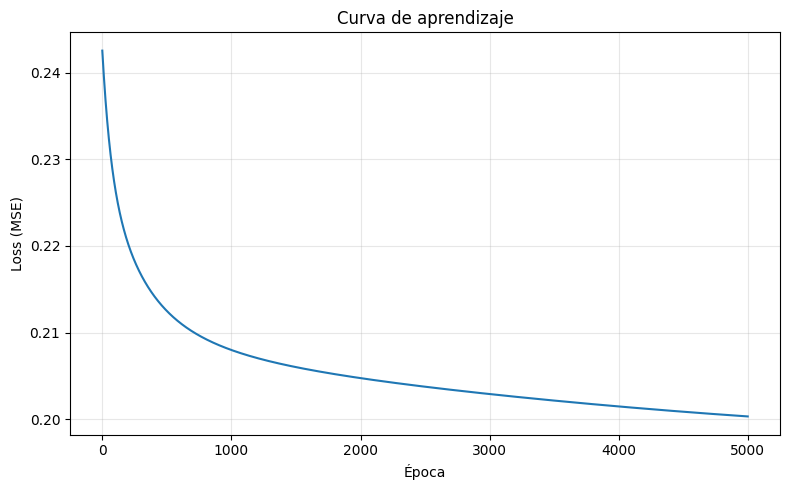

In [ ]:
# TODO (1 punto): Grafica la curva de aprendizaje (loss por época)
plt.figure(figsize=(8, 5))
plt.plot(range(epochs), loss_history, color='tab:blue', linewidth=1.5)
plt.title("Curva de aprendizaje")
plt.xlabel("Época")
plt.ylabel("Loss (MSE)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusiones

Responde a las siguientes preguntas (1 punto):

- ¿La pedida de entrenamiento disminuye?

- ¿Cuál es el mejor pérdida que alcanzaste? Menciona la cantidad de epocas y la tasa de aprendizaje usada.

### ¿La pedida de entrenamiento disminuye?

Visualmente podemos observar en los valores impresos de Train Loss que disminuye conforme avanza el entrendamiento, aunque es un decremento muy pequeño, en este ejemplo pasamos de 0.2627 a 0.2600

### ¿Cuál es el mejor pérdida que alcanzaste?

Dependiendo de la configuración puede bajar un poco más o menos pero en general la perdida se queda alrededor de 0.20 con precisión del 75%

Algunos ejemplos de corridas:

epocas = 2000
Train Loss = 0.2037
Learnrate = 0.1
Accuracy = 0.75

epocas = 5000
Train Loss = 0.2008
Learnrate = 0.2
Accuracy= 0.75


